# BnSentMix — Model 3 Final Unseen-Test Evaluation

This notebook evaluates the three **already trained and validation-selected** class-balanced focal XLM-R checkpoints on the locked unseen test split. It performs **no training, loss tuning, model selection, threshold tuning, or hyperparameter tuning**.

Primary reporting: mean ± sample SD across seeds `13, 42, 77`. Reference seed `42` is used only for the per-class diagnostic table and confusion matrix. H3 was already rejected using the predeclared validation rule; the test set is not used to redefine that decision.

In [1]:
# Cell 1 — Imports and frozen protocol constants
from pathlib import Path
import gc
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import transformers
from IPython.display import display
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_recall_fscore_support
)
from transformers import (
    AutoTokenizer, DataCollatorWithPadding,
    XLMRobertaConfig, XLMRobertaForSequenceClassification
)

EXPECTED_RAW_SHA256 = '148f23eb3dc40c1012a973efec920eaccc39700a74e5bcfb56806b0bf389029d'
EXPECTED_SPLIT_SHA256 = '7be81e52030967319d43ddc1e1feaf9817f9c3011a9b914265c34b5ce0ab8ec5'
EXPECTED_TEST_ROWS = 2973
LABELS = [0, 1, 2, 3]
LABEL_NAMES = {0: 'positive', 1: 'negative', 2: 'neutral', 3: 'mixed'}
MIXED_LABEL = 3
RUN_SEEDS = [13, 42, 77]
REFERENCE_SEED = 42
MAX_LENGTH = 128
EVAL_BATCH_SIZE = 32
CB_BETA = 0.9999
FOCAL_GAMMA = 2.0

DATA_PATH = Path('/kaggle/input/datasets/olidopu/bnsentmix/dataset.csv')
OUTPUT_DIR = Path('/kaggle/working/bnsentmix_model3_final_test')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('PyTorch:', torch.__version__)
print('Transformers:', transformers.__version__)
print('Device:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU')
print('Output directory:', OUTPUT_DIR)

PyTorch: 2.10.0+cu128
Transformers: 5.0.0
Device: Tesla T4
Output directory: /kaggle/working/bnsentmix_model3_final_test


In [2]:
# Cell 2 — Locate Model 3 artifacts and verify experiment identity
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

preferred_model_dir = Path(
    '/kaggle/input/notebooks/olidopu/final-model3/bnsentmix_model3_cb_focal'
)
if preferred_model_dir.exists():
    MODEL_INPUT_DIR = preferred_model_dir
else:
    candidates = [p.parent for p in Path('/kaggle/input').rglob('experiment_manifest.json')]
    candidates = [p for p in candidates if p.name == 'bnsentmix_model3_cb_focal']
    if len(candidates) != 1:
        raise FileNotFoundError(f'Expected one saved Model 3 folder, found: {candidates}')
    MODEL_INPUT_DIR = candidates[0]

SPLIT_PATH = MODEL_INPUT_DIR.parent / 'bnsentmix_protocol_2026' / 'bnsentmix_locked_split.csv'
TOKENIZER_DIR = MODEL_INPUT_DIR / 'tokenizer'
MANIFEST_PATH = MODEL_INPUT_DIR / 'experiment_manifest.json'
CHECKPOINTS = {seed: MODEL_INPUT_DIR / f'seed_{seed}' / 'best_state.pt' for seed in RUN_SEEDS}

assert DATA_PATH.exists(), f'Dataset not found: {DATA_PATH}'
assert SPLIT_PATH.exists(), f'Locked split not found: {SPLIT_PATH}'
assert TOKENIZER_DIR.exists(), f'Tokenizer not found: {TOKENIZER_DIR}'
assert MANIFEST_PATH.exists(), f'Experiment manifest not found: {MANIFEST_PATH}'
for seed, path in CHECKPOINTS.items():
    assert path.exists(), f'Seed {seed} checkpoint not found: {path}'
    assert path.stat().st_size > 1_000_000_000, f'Seed {seed} checkpoint appears incomplete.'

with open(MANIFEST_PATH, encoding='utf-8') as handle:
    manifest = json.load(handle)
assert manifest['dataset_sha256'] == EXPECTED_RAW_SHA256
assert manifest['split_sha256'] == EXPECTED_SPLIT_SHA256
assert manifest['run_seeds'] == RUN_SEEDS
assert np.isclose(float(manifest['beta']), CB_BETA)
assert np.isclose(float(manifest['gamma']), FOCAL_GAMMA)

raw_sha = sha256_file(DATA_PATH)
split_sha = sha256_file(SPLIT_PATH)
assert raw_sha == EXPECTED_RAW_SHA256, f'Raw dataset checksum mismatch: {raw_sha}'
assert split_sha == EXPECTED_SPLIT_SHA256, f'Locked split checksum mismatch: {split_sha}'

print('Saved Model 3:', MODEL_INPUT_DIR)
print('Locked split verified:', split_sha)
print('Focal configuration:', {'beta': manifest['beta'], 'gamma': manifest['gamma']})
print('Training class weights:', [round(x, 4) for x in manifest['class_weights']])
for seed, path in CHECKPOINTS.items():
    print(f'Seed {seed}: {path.name} ({path.stat().st_size / 1024**3:.2f} GiB)')

Saved Model 3: /kaggle/input/notebooks/olidopu/final-model3/bnsentmix_model3_cb_focal
Locked split verified: 7be81e52030967319d43ddc1e1feaf9817f9c3011a9b914265c34b5ce0ab8ec5
Focal configuration: {'beta': 0.9999, 'gamma': 2.0}
Training class weights: [0.7322, 0.6539, 0.6209, 1.9929]
Seed 13: best_state.pt (1.04 GiB)
Seed 42: best_state.pt (1.04 GiB)
Seed 77: best_state.pt (1.04 GiB)


In [3]:
# Cell 3 — Load only the sealed test partition
split_df = pd.read_csv(SPLIT_PATH)
required_columns = {'source_row_id', 'group_id', 'text', 'label', 'split'}
assert required_columns.issubset(split_df.columns), (
    f'Missing split columns: {required_columns - set(split_df.columns)}'
)
assert split_df.groupby('group_id')['split'].nunique().max() == 1, 'Group leakage detected.'

test_df = split_df.loc[split_df['split'].eq('test')].copy().reset_index(drop=True)
test_df['label'] = test_df['label'].astype(int)
assert len(test_df) == EXPECTED_TEST_ROWS, f'Expected {EXPECTED_TEST_ROWS} rows, got {len(test_df)}'
assert sorted(test_df['label'].unique().tolist()) == LABELS

distribution = (
    test_df['label'].value_counts().sort_index()
    .rename(index=LABEL_NAMES).rename('support').to_frame()
)
display(distribution)
print('Sealed unseen-test rows:', len(test_df))

,support
label,
positive,768
negative,922
neutral,1030
mixed,253


Sealed unseen-test rows: 2973


In [4]:
# Cell 4 — Recreate the exact XLM-R-base architecture and test loader
tokenizer = AutoTokenizer.from_pretrained(
    TOKENIZER_DIR, use_fast=True, local_files_only=True
)
assert tokenizer.vocab_size == 250002, f'Unexpected tokenizer vocabulary: {tokenizer.vocab_size}'

class TestDataset(Dataset):
    def __init__(self, frame):
        self.texts = frame['text'].astype(str).tolist()
        self.labels = frame['label'].astype(int).tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        encoded = tokenizer(
            self.texts[index], truncation=True, max_length=MAX_LENGTH
        )
        encoded['labels'] = self.labels[index]
        return encoded

collator = DataCollatorWithPadding(
    tokenizer=tokenizer, pad_to_multiple_of=8 if DEVICE.type == 'cuda' else None
)
test_loader = DataLoader(
    TestDataset(test_df), batch_size=EVAL_BATCH_SIZE, shuffle=False,
    collate_fn=collator, num_workers=2, pin_memory=(DEVICE.type == 'cuda')
)

ID2LABEL = {label: name for label, name in LABEL_NAMES.items()}
LABEL2ID = {name: label for label, name in LABEL_NAMES.items()}

def build_model():
    config = XLMRobertaConfig(
        vocab_size=250002, hidden_size=768, num_hidden_layers=12,
        num_attention_heads=12, intermediate_size=3072, hidden_act='gelu',
        hidden_dropout_prob=0.1, attention_probs_dropout_prob=0.1,
        max_position_embeddings=514, type_vocab_size=1,
        initializer_range=0.02, layer_norm_eps=1e-5,
        pad_token_id=1, bos_token_id=0, eos_token_id=2,
        position_embedding_type='absolute', use_cache=True,
        classifier_dropout=None, num_labels=len(LABELS),
        id2label=ID2LABEL, label2id=LABEL2ID
    )
    return XLMRobertaForSequenceClassification(config)

print('Tokenizer loaded locally. Test batches:', len(test_loader))

Tokenizer loaded locally. Test batches: 93


In [5]:
# Cell 5 — Metric and Model 3 checkpoint-loading helpers
def load_exact_state(path):
    try:
        payload = torch.load(path, map_location='cpu', weights_only=True)
    except TypeError:
        payload = torch.load(path, map_location='cpu')
    assert isinstance(payload, dict) and 'model_state_dict' in payload, (
        f'Unexpected Model 3 checkpoint format: {path}'
    )
    return payload['model_state_dict']

def calculate_metrics(labels, predictions):
    mixed_precision, mixed_recall, mixed_f1, mixed_support = (
        precision_recall_fscore_support(
            labels, predictions, labels=[MIXED_LABEL],
            average=None, zero_division=0
        )
    )
    return {
        'accuracy': float(accuracy_score(labels, predictions)),
        'macro_f1': float(f1_score(
            labels, predictions, labels=LABELS, average='macro', zero_division=0
        )),
        'weighted_f1': float(f1_score(
            labels, predictions, labels=LABELS, average='weighted', zero_division=0
        )),
        'mixed_precision': float(mixed_precision[0]),
        'mixed_recall': float(mixed_recall[0]),
        'mixed_f1': float(mixed_f1[0]),
        'mixed_support': int(mixed_support[0]),
    }

def predict_checkpoint(checkpoint_path):
    model = build_model()
    state = load_exact_state(checkpoint_path)
    model.load_state_dict(state, strict=True)
    del state
    model.to(DEVICE)
    model.eval()

    logits_parts = []
    with torch.inference_mode():
        for batch in test_loader:
            batch.pop('labels')
            batch = {key: value.to(DEVICE, non_blocking=True) for key, value in batch.items()}
            with torch.autocast(
                device_type=DEVICE.type, dtype=torch.float16,
                enabled=(DEVICE.type == 'cuda')
            ):
                logits = model(**batch).logits
            logits_parts.append(logits.float().cpu())

    logits = torch.cat(logits_parts).numpy()
    probabilities = torch.softmax(torch.from_numpy(logits), dim=1).numpy()
    predictions = logits.argmax(axis=1).astype(int)

    del model, logits_parts
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return predictions, probabilities

In [6]:
# Cell 6 — One-time unseen-test evaluation for all frozen seeds
y_true = test_df['label'].to_numpy()
seed_rows = []
seed_predictions = {}
seed_reports = {}
seed_confusions = {}

for seed in RUN_SEEDS:
    print(f'\nEvaluating frozen seed {seed} ...')
    predictions, probabilities = predict_checkpoint(CHECKPOINTS[seed])
    assert len(predictions) == len(test_df)

    metrics = calculate_metrics(y_true, predictions)
    seed_rows.append({'seed': seed, **metrics})
    seed_predictions[seed] = predictions

    report = classification_report(
        y_true, predictions, labels=LABELS,
        target_names=[LABEL_NAMES[label] for label in LABELS],
        output_dict=True, zero_division=0
    )
    seed_reports[seed] = pd.DataFrame(report).T
    seed_confusions[seed] = pd.DataFrame(
        confusion_matrix(y_true, predictions, labels=LABELS),
        index=[f'true_{LABEL_NAMES[x]}' for x in LABELS],
        columns=[f'pred_{LABEL_NAMES[x]}' for x in LABELS]
    )

    output = test_df[['source_row_id', 'group_id', 'text', 'label']].copy()
    output['label_name'] = output['label'].map(LABEL_NAMES)
    output['prediction'] = predictions
    output['prediction_name'] = output['prediction'].map(LABEL_NAMES)
    output['correct'] = output['label'].eq(output['prediction'])
    for label in LABELS:
        output[f'prob_{LABEL_NAMES[label]}'] = probabilities[:, label]
    output.to_csv(OUTPUT_DIR / f'FINAL_test_predictions_seed_{seed}.csv', index=False)
    seed_reports[seed].to_csv(OUTPUT_DIR / f'FINAL_classification_report_seed_{seed}.csv')
    seed_confusions[seed].to_csv(OUTPUT_DIR / f'FINAL_confusion_matrix_seed_{seed}.csv')
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in metrics.items()})

seed_results = pd.DataFrame(seed_rows).sort_values('seed').reset_index(drop=True)
display(seed_results.round(4))


Evaluating frozen seed 13 ...
{'accuracy': 0.7117, 'macro_f1': 0.684, 'weighted_f1': 0.7172, 'mixed_precision': 0.4258, 'mixed_recall': 0.6917, 'mixed_f1': 0.5271, 'mixed_support': 253}

Evaluating frozen seed 42 ...
{'accuracy': 0.7124, 'macro_f1': 0.6911, 'weighted_f1': 0.7136, 'mixed_precision': 0.5255, 'mixed_recall': 0.6522, 'mixed_f1': 0.582, 'mixed_support': 253}

Evaluating frozen seed 77 ...
{'accuracy': 0.7161, 'macro_f1': 0.6908, 'weighted_f1': 0.7192, 'mixed_precision': 0.4737, 'mixed_recall': 0.6759, 'mixed_f1': 0.557, 'mixed_support': 253}


,seed,accuracy,macro_f1,weighted_f1,mixed_precision,mixed_recall,mixed_f1,mixed_support
0,13,0.7117,0.6840,0.7172,0.4258,0.6917,0.5271,253
1,42,0.7124,0.6911,0.7136,0.5255,0.6522,0.5820,253
2,77,0.7161,0.6908,0.7192,0.4737,0.6759,0.5570,253


In [7]:
# Cell 7 — Primary three-seed mean ± sample SD
metric_columns = [
    'accuracy', 'macro_f1', 'weighted_f1',
    'mixed_precision', 'mixed_recall', 'mixed_f1'
]
mean_std = seed_results[metric_columns].agg(['mean', 'std']).T
mean_std.index.name = 'metric'
display(mean_std.round(4))

print('PAPER-READY MODEL 3 TEST RESULT')
for metric in metric_columns:
    print(f"{metric}: {mean_std.loc[metric, 'mean']:.4f} ± {mean_std.loc[metric, 'std']:.4f}")

,mean,std
metric,,
accuracy,0.7134,0.0024
macro_f1,0.6886,0.0040
weighted_f1,0.7167,0.0028
mixed_precision,0.4750,0.0499
mixed_recall,0.6733,0.0199
mixed_f1,0.5554,0.0275


PAPER-READY MODEL 3 TEST RESULT
accuracy: 0.7134 ± 0.0024
macro_f1: 0.6886 ± 0.0040
weighted_f1: 0.7167 ± 0.0028
mixed_precision: 0.4750 ± 0.0499
mixed_recall: 0.6733 ± 0.0199
mixed_f1: 0.5554 ± 0.0275


Reference seed: 42


,precision,recall,f1-score,support
positive,0.7490,0.7578,0.7534,768.0000
negative,0.7319,0.6779,0.7038,922.0000
neutral,0.7257,0.7243,0.7250,1030.0000
mixed,0.5255,0.6522,0.5820,253.0000
accuracy,0.7124,0.7124,0.7124,0.7124
macro avg,0.6830,0.7030,0.6911,2973.0000
weighted avg,0.7166,0.7124,0.7136,2973.0000


,pred_positive,pred_negative,pred_neutral,pred_mixed
true_positive,582,47,95,44
true_negative,74,625,159,64
true_neutral,91,152,746,41
true_mixed,30,30,28,165


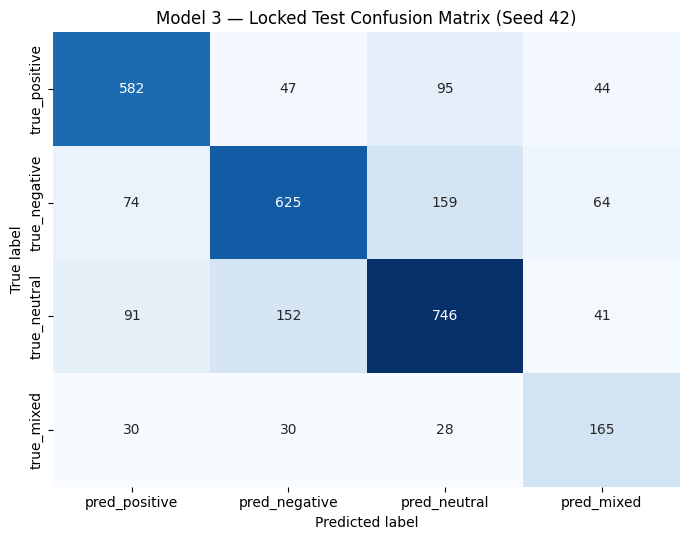

In [8]:
# Cell 8 — Predeclared reference-seed diagnostic only
print(f'Reference seed: {REFERENCE_SEED}')
display(seed_reports[REFERENCE_SEED].round(4))
display(seed_confusions[REFERENCE_SEED])

plt.figure(figsize=(7, 5.5))
sns.heatmap(
    seed_confusions[REFERENCE_SEED], annot=True, fmt='d',
    cmap='Blues', cbar=False
)
plt.title(f'Model 3 — Locked Test Confusion Matrix (Seed {REFERENCE_SEED})')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / f'FINAL_confusion_matrix_seed_{REFERENCE_SEED}.png',
    dpi=200, bbox_inches='tight'
)
plt.show()

In [9]:
# Cell 9 — Save final paper-ready summary and provenance
seed_results.to_csv(OUTPUT_DIR / 'FINAL_test_seed_results.csv', index=False)
mean_std.to_csv(OUTPUT_DIR / 'FINAL_test_mean_std.csv')

final_record = {
    'model': 'M3 Class-balanced focal XLM-R',
    'split': 'locked_final_test',
    'n_test': int(len(test_df)),
    'seeds': RUN_SEEDS,
    'reference_seed_for_diagnostics': REFERENCE_SEED,
    'per_seed': seed_results.to_dict(orient='records'),
    'mean': {metric: float(mean_std.loc[metric, 'mean']) for metric in metric_columns},
    'sample_std': {metric: float(mean_std.loc[metric, 'std']) for metric in metric_columns},
    'split_sha256': EXPECTED_SPLIT_SHA256,
    'raw_sha256': EXPECTED_RAW_SHA256,
    'max_length': MAX_LENGTH,
    'class_balanced_beta': CB_BETA,
    'focal_gamma': FOCAL_GAMMA,
    'training_class_weights': manifest['class_weights'],
    'validation_H3_supported': False
}
with open(OUTPUT_DIR / 'FINAL_test_metrics.json', 'w', encoding='utf-8') as handle:
    json.dump(final_record, handle, indent=2, ensure_ascii=False)

print('\nSaved files:')
for path in sorted(OUTPUT_DIR.iterdir()):
    print(' -', path.name)
print('\nDo not tune Model 3 or revise H3 after viewing these results.')


Saved files:
 - FINAL_classification_report_seed_13.csv
 - FINAL_classification_report_seed_42.csv
 - FINAL_classification_report_seed_77.csv
 - FINAL_confusion_matrix_seed_13.csv
 - FINAL_confusion_matrix_seed_42.csv
 - FINAL_confusion_matrix_seed_42.png
 - FINAL_confusion_matrix_seed_77.csv
 - FINAL_test_mean_std.csv
 - FINAL_test_metrics.json
 - FINAL_test_predictions_seed_13.csv
 - FINAL_test_predictions_seed_42.csv
 - FINAL_test_predictions_seed_77.csv
 - FINAL_test_seed_results.csv

Do not tune Model 3 or revise H3 after viewing these results.


## What to keep after the run

Save the Kaggle version and retain the complete `bnsentmix_model3_final_test` folder. Keep all three prediction files. Model 3's validation-stage negative result remains part of the research finding even if its unseen-test behavior differs.